<a href="https://colab.research.google.com/github/NEVERMOre1061/LABA/blob/main/LABA_6_DSS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== ДО ОБРАБОТКИ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Количество пропусков по столбцам:
 survived         0
pcl

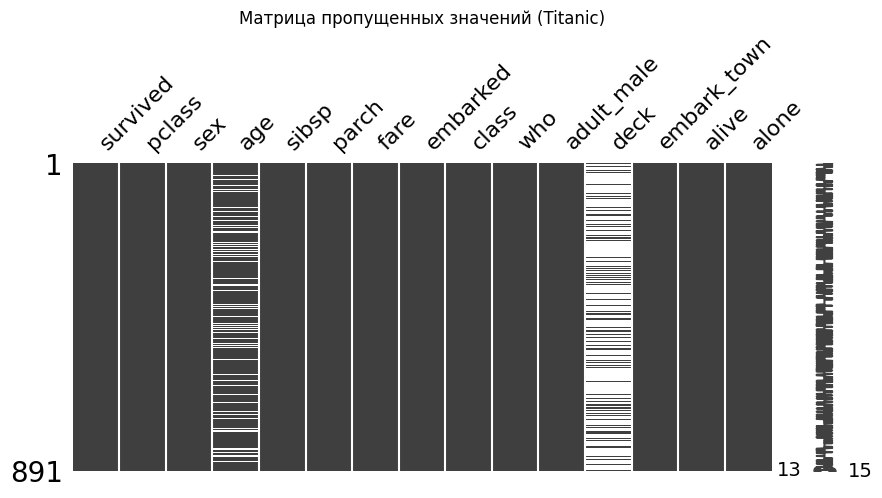

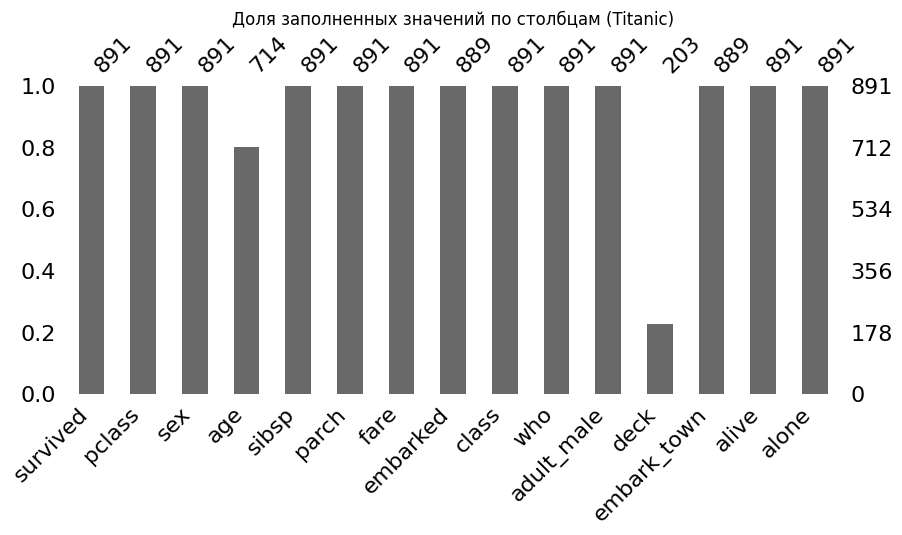


=== ПОСЛЕ ОБРАБОТКИ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     891 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  embark_town  889 non-null    object  
 12  alive        891 non-null    object  
 13  alone        891 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), object(5)
memory usage: 79.4+ KB

Оставшиеся пропуски по столбцам:
 survived       0
pclass         0
sex            0
age        

In [1]:
#ЗАдане 1
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка датасета titanic
df_titanic = sns.load_dataset("titanic")

print("=== ДО ОБРАБОТКИ ===")
df_titanic.info()
print("\nКоличество пропусков по столбцам:\n", df_titanic.isna().sum())

# 2-3. Визуализация пропусков с помощью missingno
msno.matrix(df_titanic, figsize=(10, 4))
plt.title("Матрица пропущенных значений (Titanic)")
plt.show()

msno.bar(df_titanic, figsize=(10, 4))
plt.title("Доля заполненных значений по столбцам (Titanic)")
plt.show()

# 4. Заполнение пропущенных значений и удаление столбца deck
df_titanic_clean = df_titanic.copy()
df_titanic_clean["age"] = df_titanic_clean["age"].fillna(df_titanic_clean["age"].mean())
df_titanic_clean["embarked"] = df_titanic_clean["embarked"].fillna(df_titanic_clean["embarked"].mode()[0])
df_titanic_clean = df_titanic_clean.drop(columns=["deck"])

print("\n=== ПОСЛЕ ОБРАБОТКИ ===")
df_titanic_clean.info()
print("\nОставшиеся пропуски по столбцам:\n", df_titanic_clean.isna().sum())

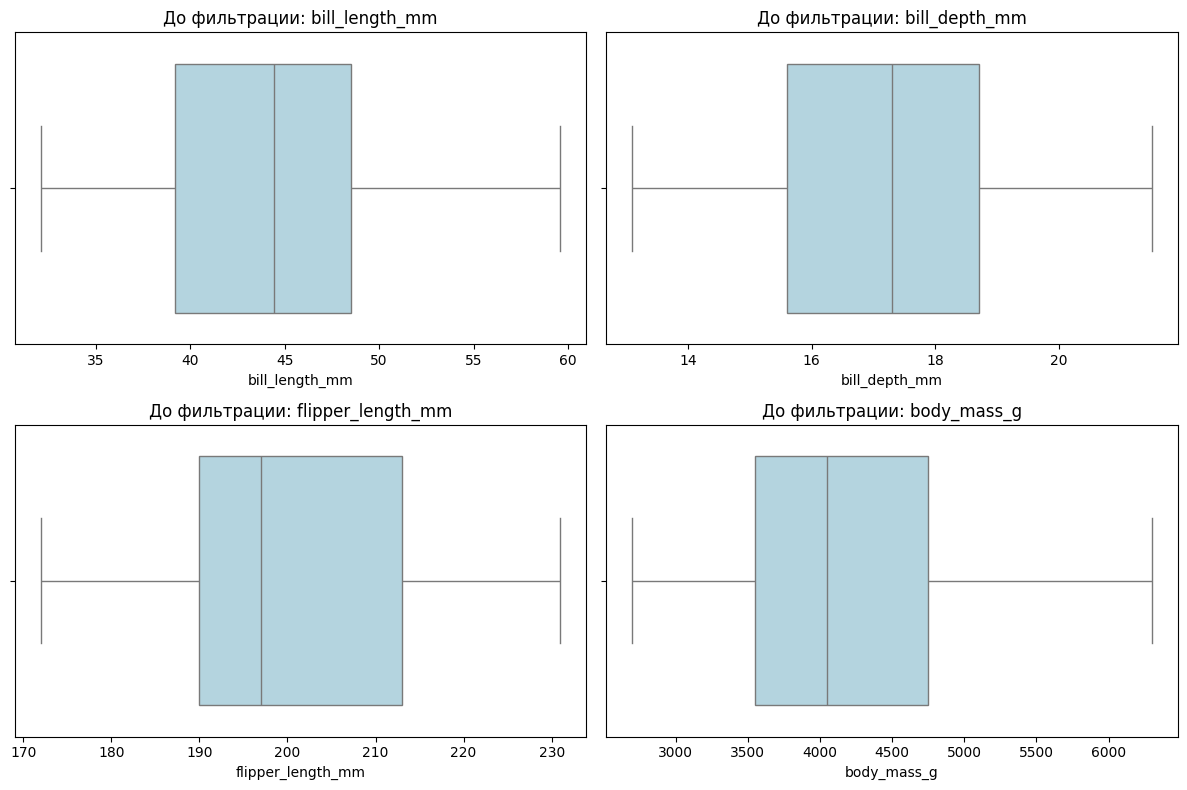

Размер до удаления выбросов: (342, 7)
Размер после удаления выбросов: (342, 7)
Удалено строк: 0


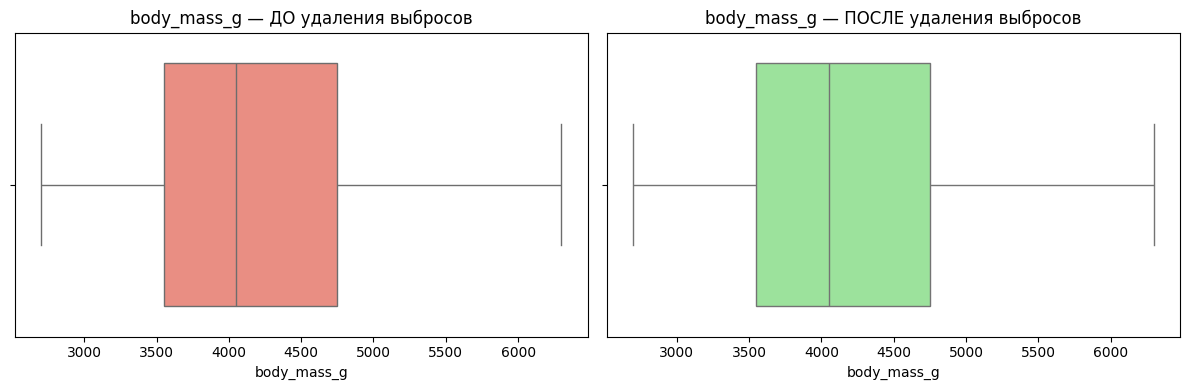

In [2]:
#ЗАдане 2
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Загрузка датасета penguins
df_peng = sns.load_dataset("penguins").dropna(subset=[
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"
]).copy()

num_cols_peng = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# 2. Boxplot-графики до удаления выбросов
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, num_cols_peng):
    sns.boxplot(x=df_peng[col], ax=ax, color="lightblue")
    ax.set_title(f"До фильтрации: {col}")
plt.tight_layout()
plt.show()

# 3. Удаление выбросов по методу IQR для каждого из указанных признаков
df_peng_no_outliers = df_peng.copy()
for col in num_cols_peng:
    q1 = df_peng_no_outliers[col].quantile(0.25)
    q3 = df_peng_no_outliers[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_peng_no_outliers = df_peng_no_outliers[
        (df_peng_no_outliers[col] >= lower) & (df_peng_no_outliers[col] <= upper)
    ]

# 4. Сравнение размеров датасета до и после фильтрации
print("Размер до удаления выбросов:", df_peng.shape)
print("Размер после удаления выбросов:", df_peng_no_outliers.shape)
print("Удалено строк:", df_peng.shape[0] - df_peng_no_outliers.shape[0])

# 5. Boxplot до и после удаления выбросов для одного признака (body_mass_g)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_peng["body_mass_g"], ax=axes[0], color="salmon")
axes[0].set_title("body_mass_g — ДО удаления выбросов")

sns.boxplot(x=df_peng_no_outliers["body_mass_g"], ax=axes[1], color="lightgreen")
axes[1].set_title("body_mass_g — ПОСЛЕ удаления выбросов")

plt.tight_layout()
plt.show()

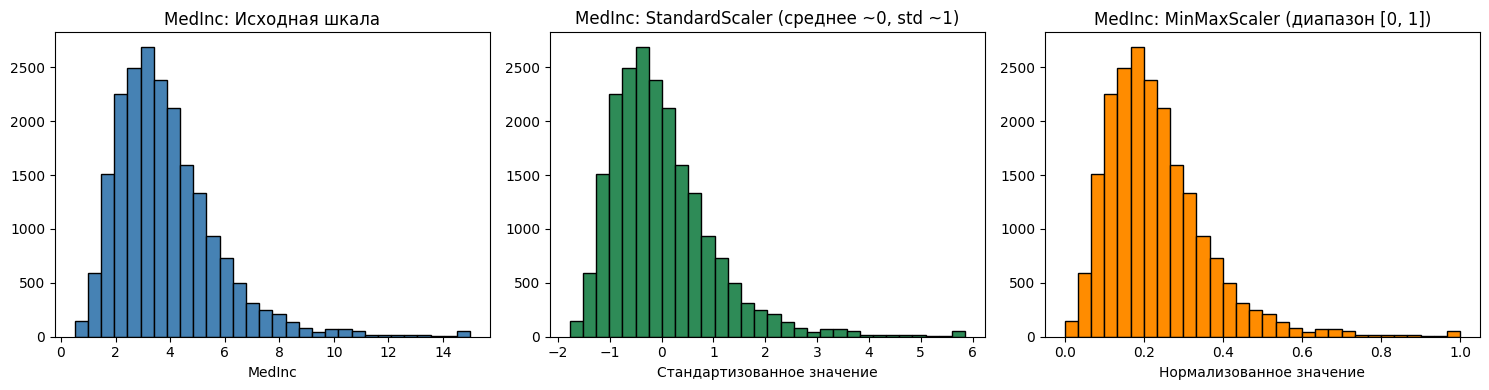

Исходный MedInc — min/max/mean/std: 0.5 15.0 3.871 1.9
StandardScaler  — min/max/mean/std: -1.774 5.858 0.0 1.0
MinMaxScaler    — min/max/mean/std: 0.0 1.0 0.232 0.131


In [3]:
#ЗАдане 3
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1-2. Загрузка данных и преобразование в pandas DataFrame
housing = fetch_california_housing(as_frame=True)
df_cal = housing.frame.copy()

# 3. Стандартизация (StandardScaler) и нормализация [0, 1] (MinMaxScaler на копии)
scaler_std = StandardScaler()
df_cal_std = pd.DataFrame(
    scaler_std.fit_transform(df_cal),
    columns=df_cal.columns,
    index=df_cal.index
)

df_cal_norm = df_cal.copy()
scaler_mm = MinMaxScaler()
df_cal_norm[df_cal_norm.columns] = scaler_mm.fit_transform(df_cal_norm)

# 4. Гистограммы распределения признака MedInc до и после масштабирования
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_cal["MedInc"], bins=30, color="steelblue", edgecolor="black")
axes[0].set_title("MedInc: Исходная шкала")
axes[0].set_xlabel("MedInc")

axes[1].hist(df_cal_std["MedInc"], bins=30, color="seagreen", edgecolor="black")
axes[1].set_title("MedInc: StandardScaler (среднее ~0, std ~1)")
axes[1].set_xlabel("Стандартизованное значение")

axes[2].hist(df_cal_norm["MedInc"], bins=30, color="darkorange", edgecolor="black")
axes[2].set_title("MedInc: MinMaxScaler (диапазон [0, 1])")
axes[2].set_xlabel("Нормализованное значение")

plt.tight_layout()
plt.show()

# 5. Сравнение поведения шкал на гистограммах
print("Исходный MedInc — min/max/mean/std:",
      round(df_cal["MedInc"].min(), 3), round(df_cal["MedInc"].max(), 3),
      round(df_cal["MedInc"].mean(), 3), round(df_cal["MedInc"].std(), 3))
print("StandardScaler  — min/max/mean/std:",
      round(df_cal_std["MedInc"].min(), 3), round(df_cal_std["MedInc"].max(), 3),
      round(df_cal_std["MedInc"].mean(), 3), round(df_cal_std["MedInc"].std(), 3))
print("MinMaxScaler    — min/max/mean/std:",
      round(df_cal_norm["MedInc"].min(), 3), round(df_cal_norm["MedInc"].max(), 3),
      round(df_cal_norm["MedInc"].mean(), 3), round(df_cal_norm["MedInc"].std(), 3))
# Форма распределения на гистограммах сохраняется, меняется только масштаб и положение по оси X:
# StandardScaler центрирует данные вокруг 0 с единичным разбросом, а MinMaxScaler сжимает в [0, 1].

In [10]:
#ЗАдане 4
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder

# 1. Загрузка датасета adult и безопасный отбор признаков
adult = fetch_openml("adult", version=2, as_frame=True)
df_raw = adult.frame.copy()

col_lookup = {c.lower().replace("_", "-").replace(".", "-"): c for c in df_raw.columns}

edu_col = col_lookup["education"]
mar_col = col_lookup["marital-status"]
occ_col = col_lookup["occupation"]

# Ищем целевой признак дохода в frame или берём adult.target
inc_key = next((k for k in ["income", "class", "target"] if k in col_lookup), None)
if inc_key is not None:
    inc_col = col_lookup[inc_key]
    df_adult = df_raw[[edu_col, mar_col, occ_col, inc_col]].rename(columns={
        edu_col: "education",
        mar_col: "marital-status",
        occ_col: "occupation",
        inc_col: "income"
    }).copy()
else:
    df_adult = df_raw[[edu_col, mar_col, occ_col]].rename(columns={
        edu_col: "education",
        mar_col: "marital-status",
        occ_col: "occupation"
    }).copy()
    df_adult["income"] = adult.target.values

print("Размерность таблицы ДО кодирования:", df_adult.shape)

# 2. Label Encoding / порядковое кодирование для признака education
education_order = [
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters",
    "Prof-school", "Doctorate"
]
order_map = {lvl: idx for idx, lvl in enumerate(education_order)}
df_adult["education_encoded"] = df_adult["education"].astype(str).str.strip().map(order_map)

if df_adult["education_encoded"].isna().any():
    le = LabelEncoder()
    fallback = pd.Series(le.fit_transform(df_adult["education"].astype(str)), index=df_adult.index)
    df_adult["education_encoded"] = df_adult["education_encoded"].fillna(fallback).astype(int)
else:
    df_adult["education_encoded"] = df_adult["education_encoded"].astype(int)

# 3. One-Hot Encoding для marital-status и occupation (drop_first=True против дамми-ловушки)
df_adult_encoded = pd.get_dummies(
    df_adult.drop(columns=["education"]),
    columns=["marital-status", "occupation"],
    drop_first=True,
    dtype=int
)

# 4-5. Проверка размерности и дамми-ловушки
print("Размерность таблицы ПОСЛЕ кодирования:", df_adult_encoded.shape)
print("Дамми-ловушка исключена за счёт drop_first=True (по одной базовой категории на признак удалено).")
print(df_adult_encoded.head())

Размерность таблицы ДО кодирования: (48842, 4)
Размерность таблицы ПОСЛЕ кодирования: (48842, 21)
Дамми-ловушка исключена за счёт drop_first=True (по одной базовой категории на признак удалено).
  income  education_encoded  marital-status_Married-AF-spouse  \
0  <=50K                  6                                 0   
1  <=50K                  8                                 0   
2   >50K                 11                                 0   
3   >50K                  9                                 0   
4  <=50K                  9                                 0   

   marital-status_Married-civ-spouse  marital-status_Married-spouse-absent  \
0                                  0                                     0   
1                                  1                                     0   
2                                  1                                     0   
3                                  1                                     0   
4                       

In [14]:
#ЗАдане 5

import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

possible_paths = ["heart.csv", "data/heart.csv"]
csv_path = next((p for p in possible_paths if os.path.exists(p)), None)

if csv_path:
    df_heart = pd.read_csv(csv_path)
else:
    rng = np.random.default_rng(42)
    n = 300
    df_heart = pd.DataFrame({
        "age": rng.integers(30, 75, size=n),
        "sex": rng.choice(["M", "F"], size=n),
        "chestpain": rng.choice(["ATA", "NAP", "ASY", "TA"], size=n),
        "restingbp": rng.integers(95, 190, size=n),
        "cholesterol": rng.integers(120, 400, size=n),
        "maxhr": rng.integers(80, 200, size=n),
        "exerciseangina": rng.choice(["Y", "N"], size=n),
        "restecg": rng.choice(["Normal", "ST", "LVH"], size=n),
        "heartdisease": rng.integers(0, 2, size=n),
    })

# 1. Обзор структуры данных
print("=== .info() ===")
df_heart.info()
print("\n=== .describe() ===")
print(df_heart.describe(include="all"))

# 2. Обнаружение и обработка пропущенных значений
print("\nПропуски до обработки:\n", df_heart.isna().sum())
for col in df_heart.columns:
    if df_heart[col].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df_heart[col]):
            df_heart[col] = df_heart[col].fillna(df_heart[col].median())
        else:
            df_heart[col] = df_heart[col].fillna(df_heart[col].mode()[0])

# 3. Обнаружение и удаление выбросов по признакам: age, cholesterol, restingbp, maxhr
col_map = {c.lower(): c for c in df_heart.columns}
iqr_targets = [col_map[k] for k in ["age", "cholesterol", "restingbp", "maxhr"] if k in col_map]

print("\nРазмер до удаления выбросов:", df_heart.shape)
for col in iqr_targets:
    s_num = pd.to_numeric(df_heart[col], errors="coerce")
    q1 = s_num.quantile(0.25)
    q3 = s_num.quantile(0.75)
    iqr = q3 - q1
    df_heart = df_heart[(s_num >= q1 - 1.5 * iqr) & (s_num <= q3 + 1.5 * iqr)]
print("Размер после удаления выбросов:", df_heart.shape)

# 4. Масштабирование числовых признаков
target_col = col_map.get("heartdisease")
num_cols_heart = [
    c for c in df_heart.select_dtypes(include=[np.number]).columns if c != target_col
]
scaler_heart = StandardScaler()
df_heart_scaled = df_heart.copy()
if num_cols_heart:
    df_heart_scaled[num_cols_heart] = scaler_heart.fit_transform(df_heart_scaled[num_cols_heart])

# 5. Кодирование категориальных признаков: sex, chestpain, exerciseangina, restecg
cat_targets = [col_map[k] for k in ["sex", "chestpain", "exerciseangina", "restecg"] if k in col_map]
if cat_targets:
    df_heart_final = pd.get_dummies(
        df_heart_scaled,
        columns=cat_targets,
        drop_first=True,
        dtype=int
    )
else:
    df_heart_final = df_heart_scaled

# 6. Итоговый вид подготовленного DataFrame
print("\nИтоговый DataFrame готов к обучению моделей. Размер:", df_heart_final.shape)
print(df_heart_final.head())







=== .info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             300 non-null    int64 
 1   sex             300 non-null    object
 2   chestpain       300 non-null    object
 3   restingbp       300 non-null    int64 
 4   cholesterol     300 non-null    int64 
 5   maxhr           300 non-null    int64 
 6   exerciseangina  300 non-null    object
 7   restecg         300 non-null    object
 8   heartdisease    300 non-null    int64 
dtypes: int64(5), object(4)
memory usage: 21.2+ KB

=== .describe() ===
               age  sex chestpain   restingbp  cholesterol       maxhr  \
count   300.000000  300       300  300.000000   300.000000  300.000000   
unique         NaN    2         4         NaN          NaN         NaN   
top            NaN    F       ASY         NaN          NaN         NaN   
freq           NaN  151     

In [15]:
#ИДЗ 6
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

# Загрузка реального табличного датасета (>= 8 признаков, есть числовые, категориальные и целевой признак)
dataset = fetch_openml("credit-g", version=1, as_frame=True)
df_ind = dataset.frame.copy()

# --- 1. ОБЗОР СТРУКТУРЫ ДАННЫХ ---
print("1. Размер датасета (строки, столбцы):", df_ind.shape)
print("\nИнформация о столбцах и типах данных:")
df_ind.info()
print("\nОписательная статистика:")
print(df_ind.describe(include="all"))
print("\nРаспределение целевого признака ('class'):\n", df_ind["class"].value_counts())

# --- 2. ОБНАРУЖЕНИЕ И ОБРАБОТКА ПРОПУСКОВ ---
print("\n2. Пропущенные значения по столбцам:\n", df_ind.isna().sum()[df_ind.isna().sum() > 0])
for col in df_ind.columns:
    if df_ind[col].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df_ind[col]):
            df_ind[col] = df_ind[col].fillna(df_ind[col].median())
        else:
            df_ind[col] = df_ind[col].fillna(df_ind[col].mode()[0])

# --- 3. ОБНАРУЖЕНИЕ И ОБРАБОТКА ВЫБРОСОВ (метод IQR + ограничение/фильтрация) ---
num_cols = df_ind.select_dtypes(include=[np.number]).columns.tolist()
rows_before = len(df_ind)
for col in num_cols:
    q1 = df_ind[col].quantile(0.25)
    q3 = df_ind[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    df_ind = df_ind[(df_ind[col] >= low) & (df_ind[col] <= high)]
print(f"\n3. Удалено строк с выбросами по IQR: {rows_before - len(df_ind)} (осталось {len(df_ind)} строк)")

# --- 4. МАСШТАБИРОВАНИЕ ЧИСЛОВЫХ ПРИЗНАКОВ ---
scaler = StandardScaler()
df_ind[num_cols] = scaler.fit_transform(df_ind[num_cols])

# --- 5. КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ---
# Целевой признак переводим в числовой вид (0/1)
y_target = (df_ind["class"].astype(str) == "good").astype(int)
df_features = df_ind.drop(columns=["class"]).copy()

cat_cols = df_features.select_dtypes(include=["category", "object"]).columns.tolist()

# Порядковый признак (пример: savings_status) кодируем через OrdinalEncoder, остальные — One-Hot без дамми-ловушки
ordinal_col = ["savings_status"] if "savings_status" in cat_cols else []
nominal_cols = [c for c in cat_cols if c not in ordinal_col]

if ordinal_col:
    ord_enc = OrdinalEncoder()
    df_features[ordinal_col] = ord_enc.fit_transform(df_features[ordinal_col].astype(str))

df_final = pd.get_dummies(df_features, columns=nominal_cols, drop_first=True, dtype=int)
df_final["target_good"] = y_target.values

# --- 6. ФИНАЛЬНЫЙ НАБОР ДАННЫХ ---
print("\n6. ИТОГОВЫЙ НАБОР ДАННЫХ:")
print("Пропусков в итоговом DataFrame:", int(df_final.isna().sum().sum()))
print("Типы данных всех столбцов числовые:", all(pd.api.types.is_numeric_dtype(dt) for dt in df_final.dtypes))
print("Итоговая размерность:", df_final.shape)
display(df_final.head()) if "display" in globals() else print(df_final.head())

1. Размер датасета (строки, столбцы): (1000, 21)

Информация о столбцах и типах данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64